In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, accuracy_score)

In [3]:
# Nạp dữ liệu
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Data_Science/Womens Clothing E-Commerce Reviews.csv"

Mounted at /content/drive


In [4]:
# Đọc file CSV
df = pd.read_csv(path, encoding='latin-1')
df.drop(columns=['Unnamed: 0'], inplace=True)
df.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [5]:
# Tổng quan dữ liệu
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              23486 non-null  int64 
 1   Age                      23486 non-null  int64 
 2   Title                    19676 non-null  object
 3   Review Text              22641 non-null  object
 4   Rating                   23486 non-null  int64 
 5   Recommended IND          23486 non-null  int64 
 6   Positive Feedback Count  23486 non-null  int64 
 7   Division Name            23472 non-null  object
 8   Department Name          23472 non-null  object
 9   Class Name               23472 non-null  object
dtypes: int64(5), object(5)
memory usage: 1.8+ MB


#preprocessing

In [6]:
# Title và Review Text nếu rỗng thay thế bằng chuỗi rỗng ""
df['Title'] = df['Title'].fillna("")
df['Review Text'] = df['Review Text'].fillna("")

# Division Name , Department Name , Class Name thay thế rỗng bằng Unknown
df['Division Name'] = df['Division Name'].fillna("Unknown")
df['Department Name'] = df['Department Name'].fillna("Unknown")
df['Class Name'] = df['Class Name'].fillna("Unknown")

# Kiểm tra lại số lượng giá trị null còn lại trong dữ liệu
df.info()
# df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Clothing ID              23486 non-null  int64 
 1   Age                      23486 non-null  int64 
 2   Title                    23486 non-null  object
 3   Review Text              23486 non-null  object
 4   Rating                   23486 non-null  int64 
 5   Recommended IND          23486 non-null  int64 
 6   Positive Feedback Count  23486 non-null  int64 
 7   Division Name            23486 non-null  object
 8   Department Name          23486 non-null  object
 9   Class Name               23486 non-null  object
dtypes: int64(5), object(5)
memory usage: 1.8+ MB


In [7]:
# Mã hóa các cột Division Name, Department Name, Class Name thành các số 1, 2, 3...
df['Division_Encoded'] = pd.factorize(df['Division Name'])[0]
df['Department_Encoded'] = pd.factorize(df['Department Name'])[0]
df['Class_Encoded'] = pd.factorize(df['Class Name'])[0]

df.head()
# display(df[['Division Name', 'Division_Encoded', 'Department Name', 'Department_Encoded', 'Class Name', 'Class_Encoded']].head())

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name,Division_Encoded,Department_Encoded,Class_Encoded
0,767,33,,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates,0,0,0
1,1080,34,,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses,1,1,1
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses,1,1,1
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants,2,2,2
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses,1,3,3


xử lý dữ liệu bị mất cân bằng

/tmp/ipykernel_4114/2602091693.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Recommended IND', palette='Set2')


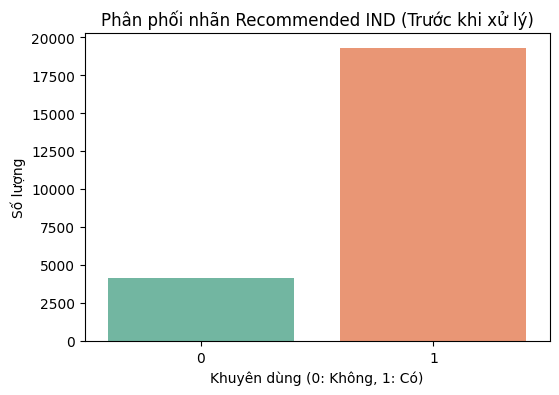

Tỷ lệ các lớp ban đầu:
Recommended IND
1    82.236226
0    17.763774
Name: proportion, dtype: float64


In [8]:
# 1. Kiểm tra phân phối nhãn trước khi xử lý
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Recommended IND', palette='Set2')
plt.title('Phân phối nhãn Recommended IND (Trước khi xử lý)')
plt.xlabel('Khuyên dùng (0: Không, 1: Có)')
plt.ylabel('Số lượng')
plt.show()

print("Tỷ lệ các lớp ban đầu:")
print(df['Recommended IND'].value_counts(normalize=True) * 100)

In [11]:
# Cài đặt thư viện imbalanced-learn
!pip install -q imbalanced-learn

import nltk
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from imblearn.over_sampling import RandomOverSampler

# Tải danh sách stopwords
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

# 1. Tiền xử lý văn bản (Lowercase, Loại bỏ ký tự đặc biệt, Tách từ, Loại bỏ stopwords)
# Chuẩn bị bản sao văn bản thô từ Title và Review Text
temp_title = df['Title'].astype(str).str.lower().str.replace(r'[^a-zA-Z0-9\s]', '', regex=True)
temp_review = df['Review Text'].astype(str).str.lower().str.replace(r'[^a-zA-Z0-9\s]', '', regex=True)

# Tách từ (Tokenization)
title_tokens = temp_title.apply(lambda x: x.split())
review_tokens = temp_review.apply(lambda x: x.split())

# Loại bỏ Stopwords
stop_words = set(stopwords.words('english'))
df['Title_tokens'] = title_tokens.apply(lambda tokens: [word for word in tokens if word not in stop_words])
df['Review Text_tokens'] = review_tokens.apply(lambda tokens: [word for word in tokens if word not in stop_words])

# 2. Ghép các token của Title và Review Text thành văn bản hoàn chỉnh
df['clean_text'] = df['Title_tokens'].apply(lambda x: ' '.join(x)) + ' ' + df['Review Text_tokens'].apply(lambda x: ' '.join(x))
X = df['clean_text']
y = df['Recommended IND']

# 3. Phân chia tập huấn luyện và kiểm thử để tránh rò rỉ thông tin (Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Tiến hành vector hóa TF-IDF
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 5. Áp dụng kỹ thuật RandomOverSampler để cân bằng phân phối nhãn của tập huấn luyện (Train)
ros = RandomOverSampler(random_state=42)
X_train_resampled, y_train_resampled = ros.fit_resample(X_train_tfidf, y_train)

# Kiểm tra phân bố lớp trước và sau khi xử lý
print("Số lượng mẫu ban đầu của tập Train:", X_train_tfidf.shape[0])
print("Số lượng mẫu sau khi xử lý imbalance (Oversampling):", X_train_resampled.shape[0])
print("\nPhân phối nhãn mới trên tập Train:")
print(y_train_resampled.value_counts(normalize=True) * 100)

Số lượng mẫu ban đầu của tập Train: 18788
Số lượng mẫu sau khi xử lý imbalance (Oversampling): 30902

Phân phối nhãn mới trên tập Train:
Recommended IND
1    50.0
0    50.0
Name: proportion, dtype: float64


#b.	Xây dựng mô hình dự đoán

Logistic Regression

=== BÁO CÁO ĐÁNH GIÁ MÔ HÌNH LOGISTIC REGRESSION ===
                     precision    recall  f1-score   support

Not Recommended (0)       0.65      0.84      0.73       835
    Recommended (1)       0.96      0.90      0.93      3863

           accuracy                           0.89      4698
          macro avg       0.81      0.87      0.83      4698
       weighted avg       0.91      0.89      0.90      4698



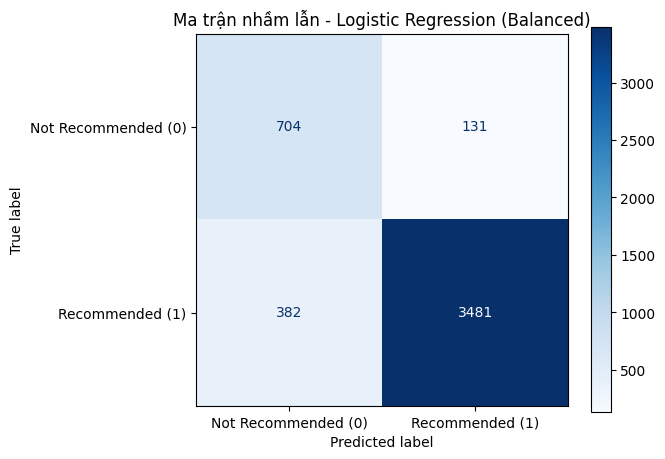

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Khởi tạo mô hình Logistic Regression (Sử dụng max_iter=1000 để đảm bảo hội tụ)
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# 2. Huấn luyện mô hình trên tập dữ liệu đã được cân bằng (Oversampled)
lr_model.fit(X_train_resampled, y_train_resampled)

# 3. Dự đoán trên tập kiểm thử
y_pred_lr = lr_model.predict(X_test_tfidf)

# 4. Hiển thị báo cáo kết quả chi tiết
print("=== BÁO CÁO ĐÁNH GIÁ MÔ HÌNH LOGISTIC REGRESSION ===")
print(classification_report(y_test, y_pred_lr, target_names=['Not Recommended (0)', 'Recommended (1)']))

# 5. Vẽ ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Recommended (0)', 'Recommended (1)'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Ma trận nhầm lẫn - Logistic Regression (Balanced)")
plt.grid(False)
plt.show()

/tmp/ipykernel_4114/2113763804.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


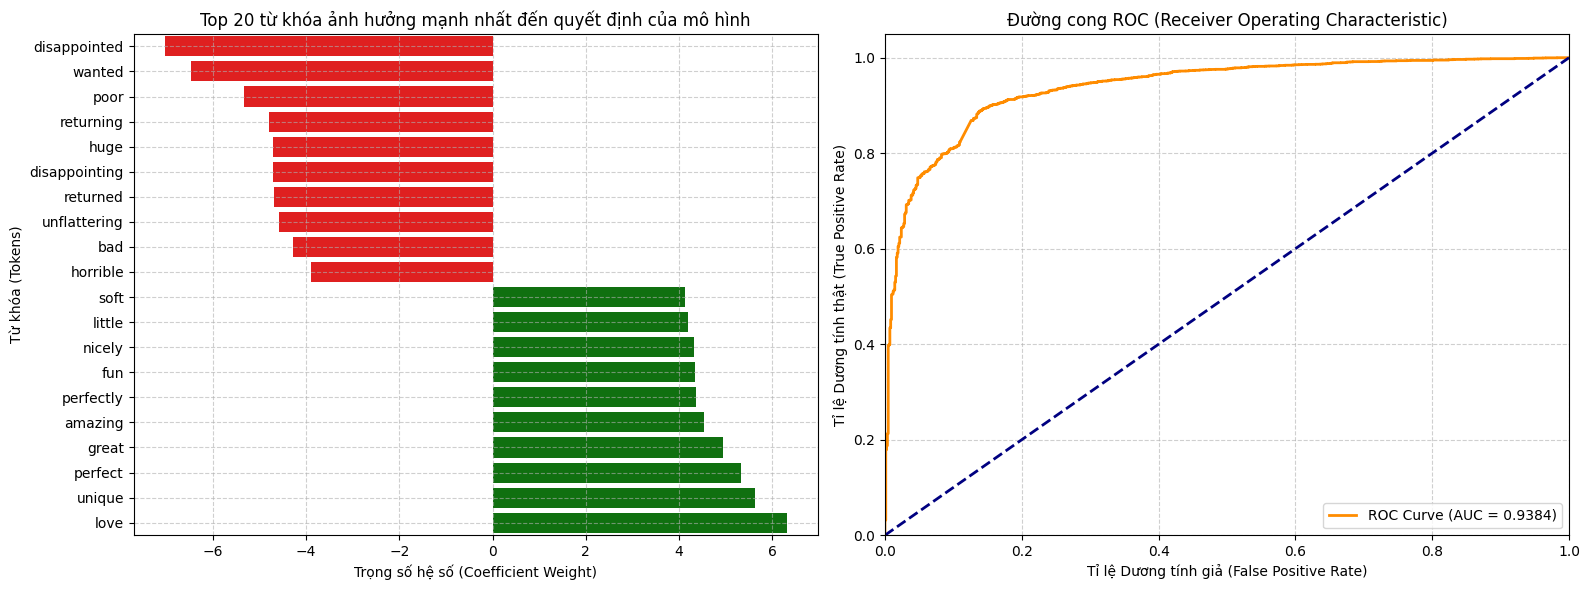

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc

# --- 1. BIỂU ĐỒ TRỰC QUAN HÓA TRỌNG SỐ TỪ VỰNG (FEATURE COEFFICIENTS) ---
# Lấy danh sách tên các từ vựng từ bộ TF-IDF
feature_names = np.array(tfidf.get_feature_names_out())
coefficients = lr_model.coef_[0]

# Tạo DataFrame chứa từ và trọng số tương ứng
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Lấy top 10 từ ảnh hưởng tích cực nhất (Khuyên dùng) và tiêu cực nhất (Không khuyên dùng)
top_positive = coef_df.sort_values(by='Coefficient', ascending=False).head(10)
top_negative = coef_df.sort_values(by='Coefficient', ascending=True).head(10)
top_features = pd.concat([top_positive, top_negative]).sort_values(by='Coefficient')

# Vẽ biểu đồ đặc trưng ảnh hưởng
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top_features,
    y='Feature',
    x='Coefficient',
    palette=["red" if c < 0 else "green" for c in top_features['Coefficient']],
    ax=ax1
)
ax1.set_title("Top 20 từ khóa ảnh hưởng mạnh nhất đến quyết định của mô hình", fontsize=12)
ax1.set_xlabel("Trọng số hệ số (Coefficient Weight)")
ax1.set_ylabel("Từ khóa (Tokens)")
ax1.grid(True, linestyle='--', alpha=0.6)

# --- 2. BIỂU ĐỒ ĐƯỜNG CONG ROC-AUC ---
# Tính toán xác suất dự đoán (probability estimates) cho lớp 1
y_probs_lr = lr_model.predict_proba(X_test_tfidf)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_probs_lr)
roc_auc = auc(fpr, tpr)

ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Tỉ lệ Dương tính giả (False Positive Rate)')
ax2.set_ylabel('Tỉ lệ Dương tính thật (True Positive Rate)')
ax2.set_title('Đường cong ROC (Receiver Operating Characteristic)', fontsize=12)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Decision Tree

Depth:  1 | Test Accuracy: 0.3025 | Class 0 Precision: 0.1996 | Class 0 Recall: 0.9713
Depth:  2 | Test Accuracy: 0.4872 | Class 0 Precision: 0.2343 | Class 0 Recall: 0.8311
Depth:  3 | Test Accuracy: 0.5392 | Class 0 Precision: 0.2559 | Class 0 Recall: 0.8347
Depth:  4 | Test Accuracy: 0.5424 | Class 0 Precision: 0.2566 | Class 0 Recall: 0.8299
Depth:  5 | Test Accuracy: 0.6433 | Class 0 Precision: 0.2999 | Class 0 Recall: 0.7545
Depth:  6 | Test Accuracy: 0.6354 | Class 0 Precision: 0.3024 | Class 0 Recall: 0.8048
Depth:  7 | Test Accuracy: 0.6279 | Class 0 Precision: 0.3011 | Class 0 Recall: 0.8275
Depth:  8 | Test Accuracy: 0.6281 | Class 0 Precision: 0.3014 | Class 0 Recall: 0.8287
Depth:  9 | Test Accuracy: 0.6281 | Class 0 Precision: 0.3007 | Class 0 Recall: 0.8240
Depth: 10 | Test Accuracy: 0.6281 | Class 0 Precision: 0.3017 | Class 0 Recall: 0.8311
Depth: 11 | Test Accuracy: 0.6322 | Class 0 Precision: 0.3032 | Class 0 Recall: 0.8240
Depth: 12 | Test Accuracy: 0.6611 | Class 0

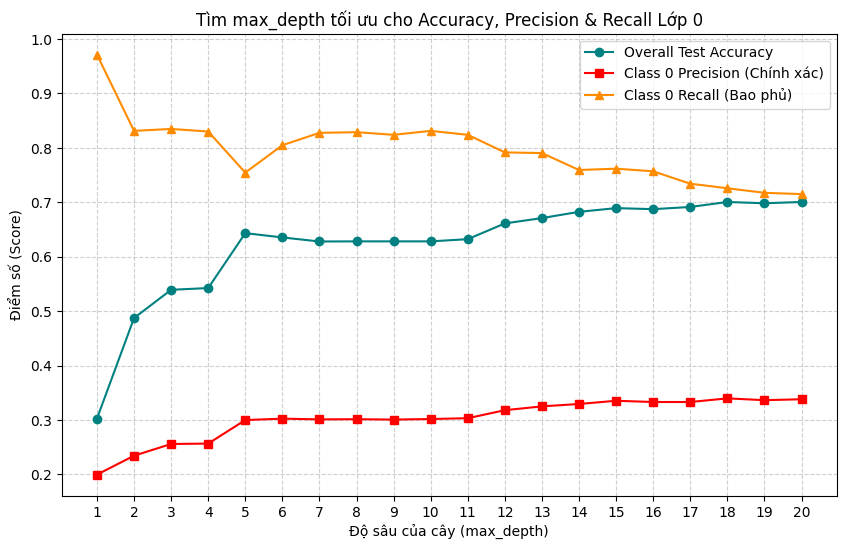

In [21]:
from sklearn.metrics import precision_score, recall_score, accuracy_score
import matplotlib.pyplot as plt

# Khởi tạo danh sách lưu kết quả mới
depths = list(range(1, 21))
test_accuracies = []
test_class0_precisions = []
test_class0_recalls = []

for depth in depths:
    # 1. Khởi tạo và huấn luyện mô hình
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train_resampled, y_train_resampled)

    # 2. Dự đoán trên tập kiểm thử
    y_test_pred = dt.predict(X_test_tfidf)

    # 3. Tính toán Accuracy tổng thể, Precision và Recall cho riêng lớp 0
    acc = accuracy_score(y_test, y_test_pred)
    prec_class0 = precision_score(y_test, y_test_pred, pos_label=0, zero_division=0)
    rec_class0 = recall_score(y_test, y_test_pred, pos_label=0, zero_division=0)

    test_accuracies.append(acc)
    test_class0_precisions.append(prec_class0)
    test_class0_recalls.append(rec_class0)

    print(f"Depth: {depth:2d} | Test Accuracy: {acc:.4f} | Class 0 Precision: {prec_class0:.4f} | Class 0 Recall: {rec_class0:.4f}")

# 4. Trực quan hóa kết quả tìm kiếm
plt.figure(figsize=(10, 6))
plt.plot(depths, test_accuracies, marker='o', label='Overall Test Accuracy', color='teal')
plt.plot(depths, test_class0_precisions, marker='s', label='Class 0 Precision (Chính xác)', color='red')
plt.plot(depths, test_class0_recalls, marker='^', label='Class 0 Recall (Bao phủ)', color='darkorange')
plt.xlabel('Độ sâu của cây (max_depth)')
plt.ylabel('Điểm số (Score)')
plt.title('Tìm max_depth tối ưu cho Accuracy, Precision & Recall Lớp 0')
plt.xticks(depths)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Nhận xét: chọn max_depth = 7

=== BÁO CÁO ĐÁNH GIÁ MÔ HÌNH DECISION TREE ===
                     precision    recall  f1-score   support

Not Recommended (0)       0.30      0.83      0.44       835
    Recommended (1)       0.94      0.58      0.72      3863

           accuracy                           0.63      4698
          macro avg       0.62      0.71      0.58      4698
       weighted avg       0.83      0.63      0.67      4698



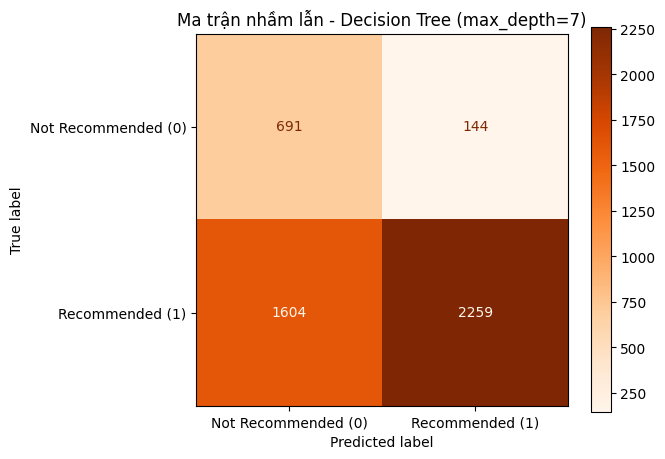

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Khởi tạo mô hình Decision Tree với tham số tối ưu max_depth = 7
dt_model = DecisionTreeClassifier(max_depth=7, random_state=42)

# 2. Huấn luyện mô hình trên tập dữ liệu đã được cân bằng (Oversampled)
dt_model.fit(X_train_resampled, y_train_resampled)

# 3. Dự đoán trên tập kiểm thử
y_pred_dt = dt_model.predict(X_test_tfidf)

# 4. Hiển thị báo cáo đánh giá kết quả chi tiết
print("=== BÁO CÁO ĐÁNH GIÁ MÔ HÌNH DECISION TREE ===")
print(classification_report(y_test, y_pred_dt, target_names=['Not Recommended (0)', 'Recommended (1)'])
)
# 5. Vẽ ma trận nhầm lẫn (Confusion Matrix) của Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Not Recommended (0)', 'Recommended (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp_dt.plot(cmap='Oranges', ax=ax, values_format='d')
plt.title("Ma trận nhầm lẫn - Decision Tree (max_depth=7)")
plt.grid(False)
plt.show()

Nhận xét: chọn max_depth = 7 mang lại kết quả tốt nhất